[Google Colab](https://colab.research.google.com/) is a hosted Jupyter notebook environment that allows anyone to run Python code via a web-browser. It provides you free computation and data storage that can be utilized by your Python code.

You can click the `+Code` button to create a new cell and enter a block of code. To run the code, click the **Run Code** button next to the cell, or press `Shift+Enter` key.

In [1]:
print('Hello World')

Hello World


### Package Management

Colab comes pre-installed with many Python packages. You can use a package by simply importing it.

In [2]:
import pandas as pd
import geopandas as gpd

Each Colab notebook instance is run on a Ubuntu Linux machine in the cloud. If you want to install any packages, you can run a command by prefixing the command with a `!`. For example, you can install third-party packages via `pip` using the command `!pip`.

> Tip: If you want to list all pre-install packages and their versions in your Colab environemnt, you can run `!pip list -v`.

In [3]:
!pip install rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.3 MB/s eta 0:00:00
  Attempting uninstall: xarray
    Found existing installation: xarray 2025.12.0
    Uninstalling xarray-2025.12.0:
      Successfully uninstalled xarray-2025.12.0


In [4]:
import rioxarray

### Data Management

Colab provides 100GB of disk space along with your notebook. This can be used to store your data, intermediate outputs and results.

The code below will create 2 folders named 'data' and 'output' in your local filesystem.

In [5]:
import os

data_folder = 'data'
output_folder = 'output'

if not os.path.exists(data_folder):
    os.mkdir(data_folder)
if not os.path.exists(output_folder):
    os.mkdir(output_folder)

We can download some data from the internet and store it in the Colab environment. Below is a helper function to download a file from a URL.

In [6]:
import requests

def download(url):
    filename = os.path.join(data_folder, os.path.basename(url))
    if not os.path.exists(filename):
      with requests.get(url, stream=True, allow_redirects=True) as r:
          with open(filename, 'wb') as f:
              for chunk in r.iter_content(chunk_size=8192):
                  f.write(chunk)
      print('Downloaded', filename)

Let's download sample dataset in colab


In [10]:
# Remove the corrupted HTML file if it exists
import os
corrupted_file = os.path.join(data_folder, 'Sentinel2_jan2023.tif')
if os.path.exists(corrupted_file):
    os.remove(corrupted_file)

# Download the raw file instead of the GitHub webpage
download('https://github.com/nilaynishant/acrs/raw/main/Data/Sentinel2_jan2023.tif')

Downloaded data/Sentinel2_jan2023.tif


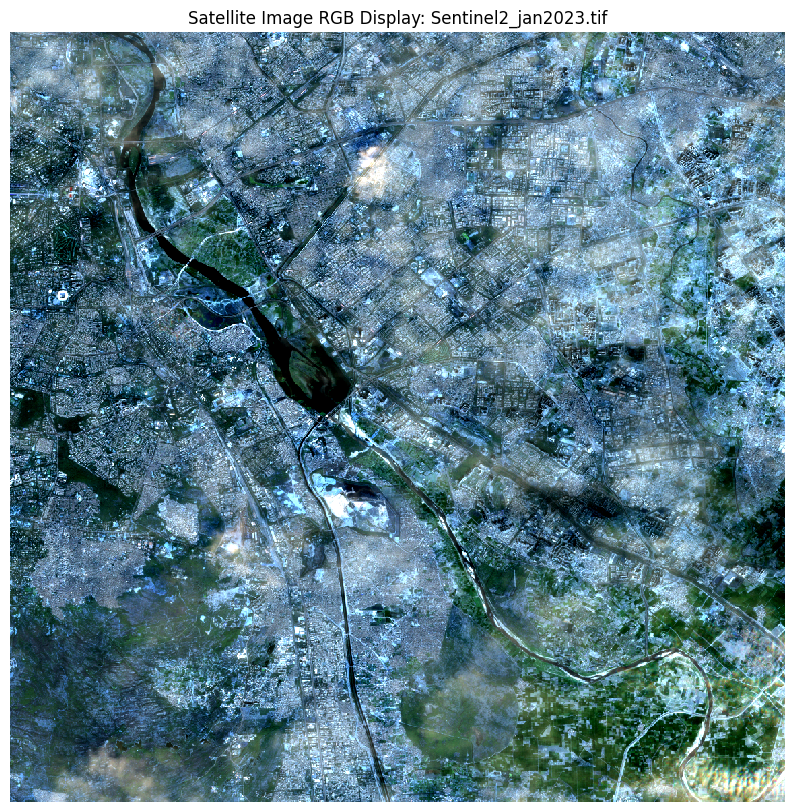

In [23]:
import os
import rioxarray
import matplotlib.pyplot as plt

tif_file = 'Sentinel2_jan2023.tif'
tif_path = os.path.join(data_folder, tif_file)

raster = rioxarray.open_rasterio(tif_path)
rgb_raster = raster.isel(band=slice(0, 3))

fig, ax = plt.subplots(figsize=(10, 10))
rgb_raster.plot.imshow(ax=ax, robust=True)

ax.set_axis_off()   # hides axis lines, ticks, tick labels and axis labels
ax.set_title("Satellite Image RGB Display: Sentinel2_jan2023.tif")

plt.show()

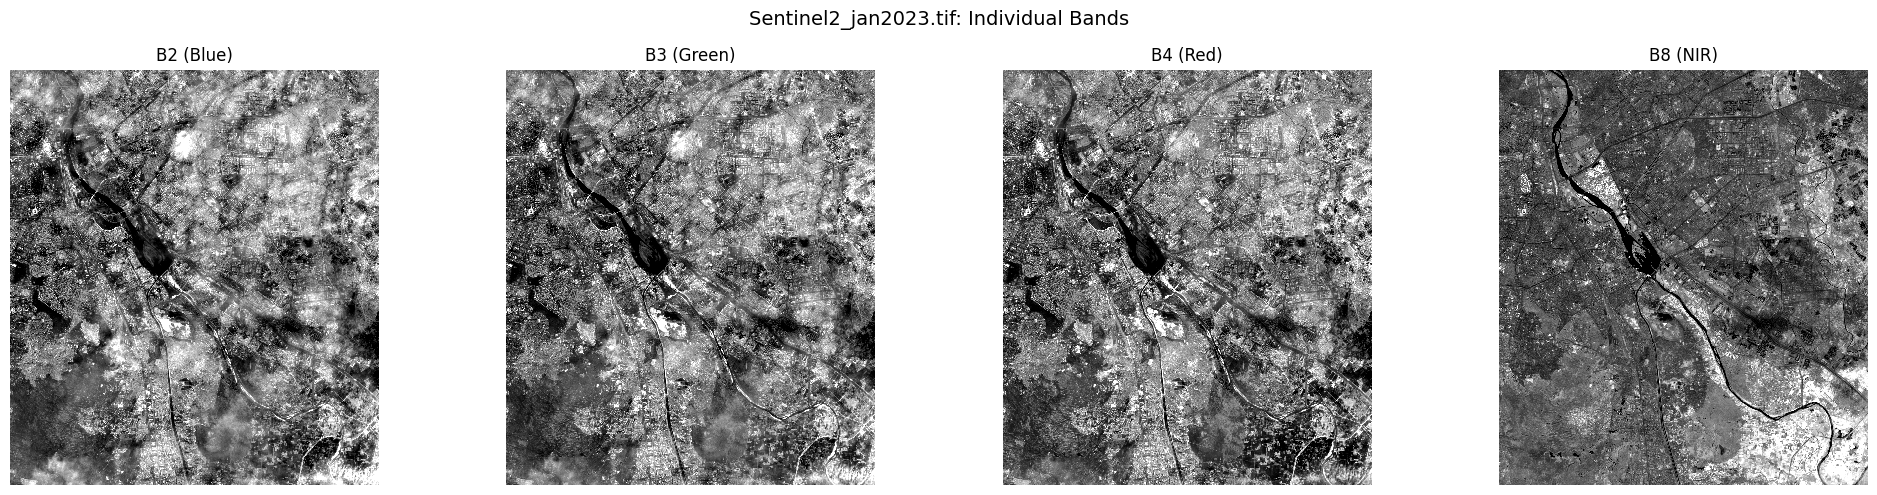

In [28]:
import os
import rioxarray
import matplotlib.pyplot as plt

tif_file = 'Sentinel2_jan2023.tif'
tif_path = os.path.join(data_folder, tif_file)

raster = rioxarray.open_rasterio(tif_path)

# Short titles so they fit above each panel (edit to match your band order)
band_names = ['B2 (Blue)', 'B3 (Green)', 'B4 (Red)', 'B8 (NIR)']

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for i, ax in enumerate(axes):
    raster.isel(band=i).plot.imshow(
        ax=ax,
        cmap='gray',
        robust=True,
        add_colorbar=False,
    )
    ax.set_title(band_names[i])
    ax.set_aspect('equal')
    ax.set_axis_off()

fig.suptitle("Sentinel2_jan2023.tif: Individual Bands", fontsize=14)
plt.tight_layout()
plt.show()

### Using the Terminal (Advanced)

A recent update to Google Colab added support for [Terminal](https://medium.com/google-colab/colab-terminal-is-now-free-for-all-users-9a10eaef2ca8) within Google Colab. Terminal access allows you to run Linux commands directly on your Colab Runtime and gives you advanced capabilities to do more analysis in the cloud.

You can open the terminal by clicking on the **Terminal** button in the bottom left of the notebook.

The Terminal opens in the default `/content` directory. As we have created a `data` folder, we can use the `cd` command to navigate to it and `ls` command to list the files.

```
cd data
ls
```

#### Downloading Data

As we have access to standard Linux commands, we can use `wget` command to download data from the internet.

```
wget https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_annual/tifs/chirps-v2.0.2024.tif
```

#### Running Command-Line Utilities

The Terminal offers us a great interface to run command-line utilities for data validation and conversion.

While working on cloud-native data analysis, you will often need to convert data into cloud-native data formats, such as Cloud-Optimized GeoTIFF (COG). Let's see how you can accomplish this on the Colab Terminal.

Let's install the [`rio-cogeo`](https://cogeotiff.github.io/rio-cogeo/) package which has features that help validate Cloud Optimized GeoTIFF files.

```
pip install rio-cogeo
```

This package installs the [`rio`](https://cogeotiff.github.io/rio-cogeo/CLI/#validate) command line tool that we can use to  check if the downloaded tif is a valid COG.

```
rio cogeo validate chirps-v2.0.2024.tif
```

*The downloaded file fails the validation as it is not a Cloud-Optimized GeoTIFF.*

Let's convert the file to a proper COG using [GDAL](https://gdal.org/).

Run the following command to install the `gdal-bin` package.

```
apt-get install gdal-bin
```

 We can use the [`gdal_translate`](https://gdal.org/en/stable/programs/gdal_translate.html) command to convert the downloaded GeoTIFF file to a Cloud-Optimized GeoTIFF.

```
gdal_translate -of COG chirps-v2.0.2024.tif chirps-v2.0.2024_cog.tif
```

> Note: GDAL tools have a new interface starting from v3.11. Colab Runtime currently has GDAL v3.8.

Now we run the validator on the converted file. The valiation will now be successful.

```
rio cogeo validate chirps-v2.0.2024_cog.tif
```

We can copy the resulting file to our Google Drive folder using the Linux `cp` command.

```
cp chirps-v2.0.2024_cog.tif /content/drive/MyDrive/python-remote-sensing/
```